# Assignment 4 — AI risk sentiment and equity returns

**Panagiotis Housos | ph2606 | FRE-GY 7871A | Fall 2026**

September 8–30, 2026, through the final 16:00 New York market close. Later text lies outside the return window. The six-page PDF and this notebook share the same computed exhibits. See README for acquisition and refresh; raw/derived datasets are intentionally excluded from Git.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
assert (ROOT / 'src/analysis.py').exists(), 'Run from the repository root.'
pd.set_option('display.max_columns', 14)
pd.set_option('display.max_colwidth', 65)
pd.set_option('display.precision', 4)
from src.config import CUTOFF
print('Observed cutoff:', CUTOFF, '| Requested end: 2026-09-30')

Observed cutoff: 2026-09-30 | Requested end: 2026-09-30


## Recalculate from the cached observations

The next cell recalculates the wording measures, tests and charts from locally cached source records. No observations are downloaded or simulated here. Synthetic tests are separate from study data. Language audit is a detector sensitivity and must be acquired before this cell to reproduce all specifications.

In [2]:
from src.text_features import build as score_text
from src.analysis import analyze
from src.figures import build as draw_figures
assert (ROOT / 'data/processed/language_audit.csv').exists(), 'Run python -m src.language_audit first.'
score_text()
panel = analyze()
draw_figures()
summary = json.loads((ROOT / 'outputs/summary.json').read_text())
assert panel.index.is_unique
assert panel[['basket','spy','qqq']].notna().all().all()
print('Computed all exhibits from observed source data.')

kind    included_analysis
news    False                  737
        True                  5686
social  False                  262
        True                 43658


{
  "cutoff": "2026-09-30",
  "sessions": 17,
  "final_day_partial_calendar": true,
  "text_window_end": "2026-09-30T16:00:00-04:00",
  "window_definition": "Requested dates through final US cash-market close; subsequent text is outside the return window.",
  "documents": {
    "HN comments": 39077,
    "HN stories": 4581,
    "News headlines": 5686
  },
  "risk_documents": {
    "HN comments": 6442,
    "HN stories": 598,
    "News headlines": 1143
  },
  "returns": {
    "basket": 2.7167164600557125,
    "spy": -0.735696009131559,
    "qqq": 3.001679501943455,
    "buy_hold": 2.6510684150902852
  },
  "postclose_records_not_in_market_regression": 243,
  "core_family_size": 6,
  "sensitivity_family_size": 16,
  "news_sources": 1291
}
   outcome       predictor  lag  n status      f      p  df_resid  coefficient_lag1  effect_per_01  ci_low_per_01  ci_high_per_01  coefficient_sum  r_squared  ljung_box_p first_date  last_date  wild_p  bootstrap_draws       family  p_holm
    basket d_bal

Computed all exhibits from observed source data.


## 1  Research question and equity basket

**Research question.** Did the AI-risk discussion following Evan Hubinger’s September 8 X post predict returns in AI equities, and did coverage display a negativity pattern comparable to the assigned COVID-news study? The post motivates the window; the analysis does not identify its isolated causal effect. [1, 2]

**Observed answer.** Risk-headline mean sentiment rose between the opening and closing periods. The six-stock basket returned **2.72%**, versus **-0.74% for SPY** and **3.00% for QQQ**. No core Granger test survives Holm correction at 5%. The US-versus-international negativity coefficient points in the direction opposite to the COVID paper’s finding. The two measures do not provide equally strong evidence for this source-group difference.

**Observation window.** September 8–30, 2026, covering 17 completed market sessions. Text is frozen at 16:00 New York time on September 30, the final market close. September 30 text after 16:00 is outside this aligned study; the final calendar day is therefore partial. No future observation or missing return is filled.

| Ticker | AI exposure used to select basket | Initial / target weight | Window return |
| --- | --- | --- | --- |
| NVDA | Accelerators | 16.67% | -0.75% |
| MSFT | Cloud / models | 16.67% | 2.64% |
| GOOGL | Cloud / models | 16.67% | 1.66% |
| AMZN | Cloud / models | 16.67% | -3.62% |
| META | Models / platforms | 16.67% | 17.67% |
| AVGO | AI infrastructure | 16.67% | -1.70% |

Weights are fixed at $1/6$ before examining returns. Each session’s simple basket return is the mean of six dividend/split-adjusted returns: $r^B_t=100\sum_i w_i(P^*_{i,t}/P^*_{i,t-1}-1)$. Rebalancing is at the preceding close; compounded returns exclude fees. September 4 supplies the baseline because September 7 was Labor Day. SPY is the broad benchmark; QQQ is the technology-heavy comparison. The sample is deliberately an AI-exposed basket, not a pure-play AI industry index. [8]

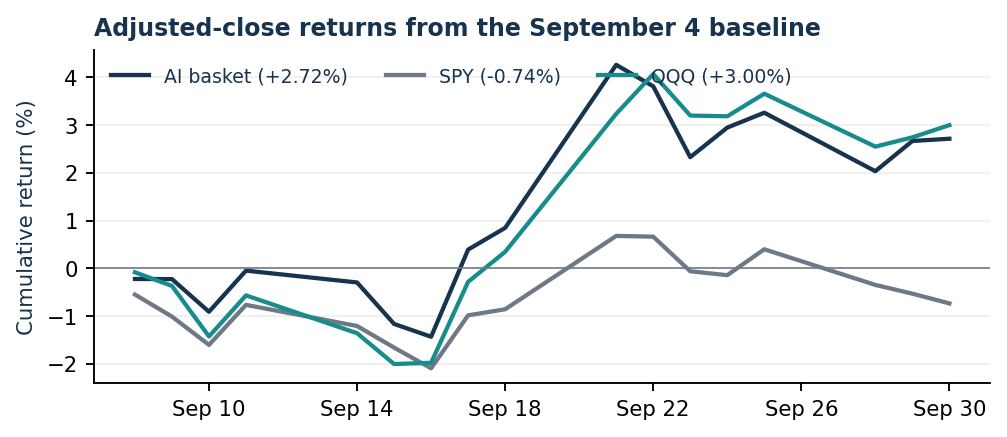

In [3]:
display(Image(filename=str(ROOT / 'outputs/market_returns.png')))

Figure 1. Adjusted-close cumulative returns, September 8–30. Lines describe realized returns, not returns caused by the X post.

In [4]:
print('constituents')
display(pd.read_csv(ROOT / 'data/processed/constituents.csv'))

constituents


,ticker,weight,baseline_date,baseline_adjusted,last_date,last_adjusted,cumulative_return_pct
0,NVDA,0.1667,2026-09-04,230.1025,2026-09-30,228.38,-0.7486
1,MSFT,0.1667,2026-09-04,499.7000,2026-09-30,512.90,2.6416
2,GOOGL,0.1667,2026-09-04,338.4600,2026-09-30,344.08,1.6605
3,AMZN,0.1667,2026-09-04,258.5100,2026-09-30,249.15,-3.6208
4,META,0.1667,2026-09-04,616.2836,2026-09-30,725.18,17.6698
5,AVGO,0.1667,2026-09-04,357.2495,2026-09-30,351.19,-1.6961
6,SPY,0.0000,2026-09-04,768.2822,2026-09-30,762.63,-0.7357
7,QQQ,0.0000,2026-09-04,718.2116,2026-09-30,739.77,3.0017


## 2  Data collection, filtering and timing

Collection begins with **broad AI terms**, not “danger,” “doom,” or negative stock returns. Four fixed Google News query families cover artificial intelligence, OpenAI/ChatGPT, Anthropic/Claude, and AI with basket-company names; the Guardian AI archive supplies publisher pages. Nine Hacker News (HN) query terms cover AI, artificial intelligence, LLM, ChatGPT, OpenAI, Anthropic, superintelligence, machine learning and AGI. Daily HN queries are recursively split in time to resolve the 1,000-result ceiling. [6, 7]

| Stage | News | Hacker News |
| --- | --- | --- |
| Retrieved hits / unique HN IDs | 9,818 rows | 45,507 IDs |
| Duplicate removals in collection | 2,426 | 289 |
| Own headline / text lacks AI anchor | 684 | 1,125 |
| Other collection exclusions | 285 | 173 |
| After collection | 6,423 | 43,920 |
| Additional analysis exclusions | 737 | 262 |
| Final analysis corpus | 5,686 headlines | 39,077 comments + 4,581 stories |
| Risk / safety subset | 1,143 headlines | 6,442 comments + 598 stories |

News collection excludes 210 out-of-window items, 41 live/audiovisual items, 32 short headlines and 2 items modified after cutoff. HN excludes 5 non-story/comment items, 161 texts under three words and 7 link-spam cases; the notebook checks the filter reconciliation. Analysis excludes known nonmedia sources, then requires five words and an AI anchor in the scored text. Exact normalized text duplicates retain the earliest eligible availability within each medium. No fuzzy matching or verified-bot classifier is claimed.

**Reach and automation.** Followers, views and comment scores are unavailable in HN; no fictional thresholds are applied. Story points and comment counts are retrieval-time snapshots. A sensitivity sample excludes story points below 5, bot-like account names and authors exceeding 100 retrieved records in a day. The collector’s stricter sample contains 40,198 records before the final text filters. Suspected automation is not proof of a bot. The main market signal uses comments, so a story-points threshold cannot directly filter it.

**Coverage limits.** The final news sample spans 1,291 source labels after alias normalization. However, 95 of 96 RSS requests reach 100 items: this is ranked, capped retrieval, not a media census. GDELT was rate-limited. X, Reddit and Bluesky supplied no usable corpus; HN represents a technology community, not all social-media users. Near-duplicate syndication and unidentified promotional sources can remain. English-oriented sources are supplemented by a detector-score sensitivity, not assumed to be perfectly English.

**Market timing.** RSS publication times often look normalized, so each RSS headline becomes usable at the next New York midnight. Guardian items use the later publication/modification clock; HN uses its timestamp. Each item enters the first 16:00 New York close at or after availability; weekend text enters Monday. Items whose conservative availability falls after the September 30 close contribute only to descriptive comparisons. Text published after the final 16:00 cutoff is excluded. Latest wording is not a verified historical vintage; no live trading performance is claimed.

In [5]:
print('analysis_filter_audit')
display(pd.read_csv(ROOT / 'data/processed/analysis_filter_audit.csv'))

analysis_filter_audit


,kind,analysis_exclusion,n
0,news,NaN,5686
1,news,exact_text_duplicate_within_medium,429
2,news,known_nonmedia_source,274
3,news,no_AI_anchor_in_scored_text,5
4,news,under_5_words,29
5,social,NaN,43658
6,social,exact_text_duplicate_within_medium,6
7,social,under_5_words,256


## 3  Sentiment measurement and observed trend

Risk-topic detection and emotional wording are separate steps. Published regular expressions flag existential/control risk, misuse (including hacking and deception), and societal harms or safety. Positive mitigation discussions remain in the risk subset. VADER preserves negation, punctuation and capitalization; compound scores range from −1 to +1 and values at or below −0.05 are labeled negative. The Hu–Liu check divides negative-token counts by all alphabetic tokens, without stopword removal. Neither measure is an extinction probability or a validated attitude toward AI. [3–5]

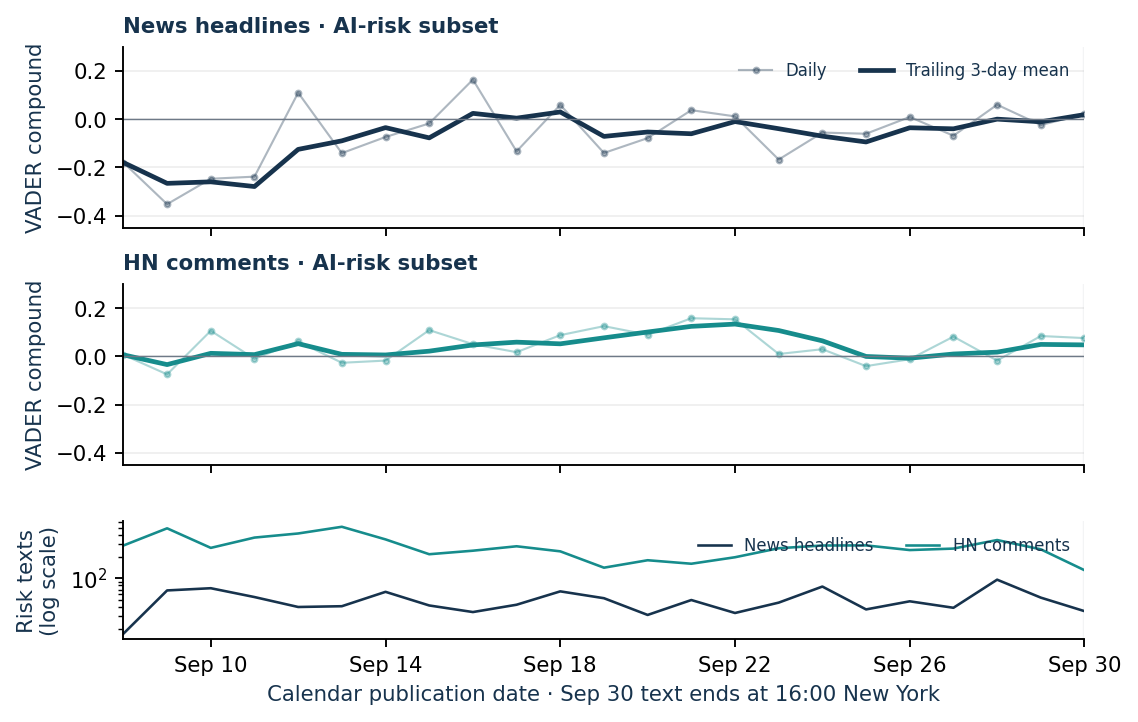

In [6]:
display(Image(filename=str(ROOT / 'outputs/sentiment_trends.png')))

Figure 2. Daily risk/safety wording with trailing averages for display only. Regressions use unsmoothed observations; no values are filled for missing days.

| Risk / safety sample | Sep 8–14 mean | Sep 22–30 mean | Change |
| --- | --- | --- | --- |
| News headlines | -0.161 | -0.031 | 0.130 |
| HN comments | 0.007 | 0.041 | 0.034 |
| HN stories | -0.067 | 0.016 | 0.083 |

Calendar days receive equal weight in these opening/closing-period comparisons; the final day ends at 16:00. The news-negative share moves from 55.3% to 40.6%; comments move from 47.9% to 45.0%. Daily reversals and changes in retrieved composition prevent treating this as a monotonic public-opinion trend. None of the time slopes survives Holm correction at 5%. The news slope is borderline (adjusted p=0.050002), so the trend should be read descriptively.

**Context audit.** An AI-assisted review of 60 real texts found quotation and target errors: a headline about scrutiny of OpenAI’s safety committee receives positive VADER valence, while a comment criticizing blame placed on AI receives negative valence. “Hacks” can receive zero valence. The class readings motivate comparing methods and inspecting these cases; their benchmark accuracies do not transfer to this corpus. No independent human accuracy estimate is available. [3–5]

In [7]:
print('trends')
display(pd.read_csv(ROOT / 'outputs/trends.csv'))

trends


,medium,early_mean,late_mean,change,early_negative_share,late_negative_share,slope_per_day,slope_hac_p,early_days,late_days,slope_holm_p
0,HN comments,0.0069,0.0410,0.0341,0.4792,0.4498,0.0018,0.2743,7,9,0.2743
1,HN stories,-0.0665,0.0160,0.0825,0.4706,0.4157,0.0047,0.0501,7,9,0.1002
2,News headlines,-0.1606,-0.0307,0.1298,0.5528,0.4064,0.0085,0.0167,7,9,0.0500


In [8]:
print('topic_summary')
display(pd.read_csv(ROOT / 'outputs/topic_summary.csv'))

topic_summary


,medium,topic,n,vader,negative,hu_negative
0,HN comments,existential,1660,-0.0235,0.4940,0.0434
1,HN comments,misuse,2342,0.0185,0.4671,0.0427
2,HN comments,other_AI,32635,0.2326,0.2855,0.0267
3,HN comments,societal,2440,0.0769,0.4398,0.0408
4,HN stories,existential,138,-0.2812,0.6594,0.0890
5,HN stories,misuse,237,0.0249,0.3840,0.0684
6,HN stories,other_AI,3983,0.1003,0.1948,0.0281
7,HN stories,societal,223,0.1667,0.3229,0.0646
8,News headlines,existential,230,-0.3816,0.7739,0.1049
9,News headlines,misuse,449,-0.1015,0.4588,0.0841


## 4  Does sentiment Granger-predict returns?

The source-balanced risk score is $S_t=(\bar{s}^{news}_t+\bar{s}^{comments}_t)/2$: equal source weights prevent comment volume from overwhelming news. A missing component makes the index missing. With $\Delta S_t=S_t-S_{t-1}$ and primary outcome $y_t=r^B_t-r^{SPY}_t$, estimate

$$y_t=\alpha+\sum_{j=1}^{p}\phi_j y_{t-j}+\sum_{j=1}^{p}\beta_j\Delta S_{t-j}+\varepsilon_t,\qquad H_0:\beta_1=\cdots=\beta_p=0.$$

Lag one is primary; lag two is a sensitivity. The F-test asks whether lagged sentiment adds predictive information beyond lagged returns. Lags are formed on the full session calendar before incomplete equations are deleted. Timing and missing observations leave **14 usable equations and 11 residual degrees of freedom** at lag one, and 13/8 at lag two. Thousands of documents do not increase this time-series sample size. [9]

| Outcome | Lags | N | 0.1 × β₁ | F | p | Holm p | Wild p |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Basket | 1 | 14 | -1.047 | 4.49 | 0.058 | 0.288 | 0.240 |
| Basket | 2 | 13 | -1.030 | 3.31 | 0.090 | 0.325 | 0.450 |
| Basket − SPY | 1 | 14 | -0.517 | 3.67 | 0.082 | 0.325 | 0.368 |
| Basket − SPY | 2 | 13 | -0.491 | 4.83 | 0.042 | 0.253 | 0.390 |
| Basket − QQQ | 1 | 14 | -0.378 | 3.68 | 0.081 | 0.325 | 0.047 |
| Basket − QQQ | 2 | 13 | -0.335 | 2.31 | 0.162 | 0.325 | 0.219 |

Table 3. Effects are percentage points of return per 0.1-point larger prior sentiment change. At two lags, the coefficient shown is the first lag; F tests both jointly. Holm adjusts 6 core F-tests together. Wild p-values are separate 4,999-draw restricted-residual fixed-design diagnostics; lagged regressors are held fixed. Conventional intervals and both p-value methods remain fragile in this sample.

The primary estimate is **-0.517 pp** per +0.1 change, with 95% interval **[-1.111, 0.077]**, raw p=0.082, Holm p=0.325 and wild p=0.368. Its negative sign means improved wording precedes weaker relative returns in this fit. This is a conditional association, not evidence that sentiment caused gains or losses. The smallest core adjusted p is 0.253.

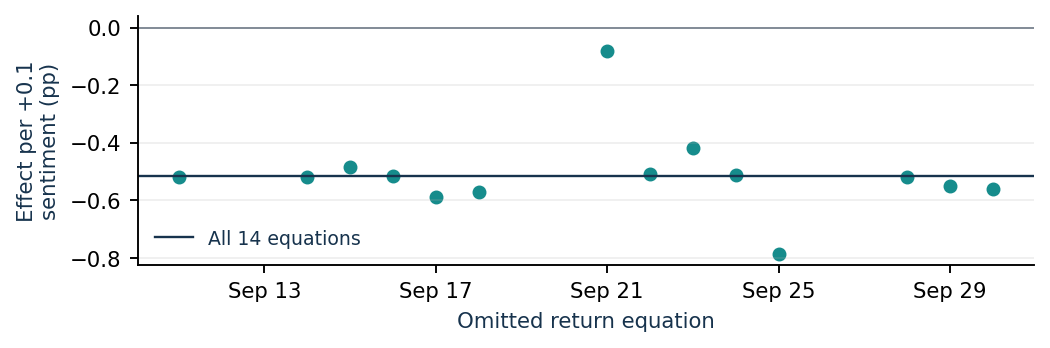

In [9]:
display(Image(filename=str(ROOT / 'outputs/influence.png')))

Figure 3. Primary coefficient after deleting one return equation, with all lag definitions preserved.

Omitting September 21, the most influential equation, changes the estimate to -0.081 pp (p=0.782). HN-only risk tone gives p=0.778; reverse-direction testing gives p=0.794. Source/author/thread weighting, stricter filtering, language restriction, extra delay and Hu–Liu checks appear in the notebook. None survives its sensitivity-family Holm correction. ADF and residual diagnostics are weak in such short samples. Even a Granger rejection would not identify structural causation.

In [10]:
print('granger_core')
display(pd.read_csv(ROOT / 'outputs/granger_core.csv'))

granger_core


,outcome,predictor,lag,n,status,f,p,...,ljung_box_p,first_date,last_date,wild_p,bootstrap_draws,family,p_holm
0,basket,d_balanced_risk,1,14,ok,4.4935,0.0576,...,0.2749,2026-09-11,2026-09-30,0.2400,4999,core_forward,0.2880
1,basket,d_balanced_risk,2,13,ok,3.3061,0.0898,...,0.3903,2026-09-14,2026-09-30,0.4498,4999,core_forward,0.3250
2,spread,d_balanced_risk,1,14,ok,3.6678,0.0818,...,0.2793,2026-09-11,2026-09-30,0.3682,4999,core_forward,0.3250
3,spread,d_balanced_risk,2,13,ok,4.8282,0.0421,...,0.9848,2026-09-14,2026-09-30,0.3902,4999,core_forward,0.2529
4,spread_qqq,d_balanced_risk,1,14,ok,3.6835,0.0813,...,0.4634,2026-09-11,2026-09-30,0.0474,4999,core_forward,0.3250
5,spread_qqq,d_balanced_risk,2,13,ok,2.3066,0.1618,...,0.6152,2026-09-14,2026-09-30,0.2186,4999,core_forward,0.3250


In [11]:
print('granger_sensitivity')
display(pd.read_csv(ROOT / 'outputs/granger_sensitivity.csv'))

granger_sensitivity


,outcome,predictor,lag,n,status,f,p,...,ljung_box_p,first_date,last_date,wild_p,bootstrap_draws,specification,p_holm
0,spread,d_balanced,1,14,ok,0.8352,0.3804,...,0.8933,2026-09-11,2026-09-30,0.4960,4999,d_balanced,1.0000
1,spread,d_news_risk,1,14,ok,3.4002,0.0923,...,0.6731,2026-09-11,2026-09-30,0.5850,4999,d_news_risk,1.0000
2,spread,d_social_risk,1,15,ok,0.0832,0.7779,...,0.8342,2026-09-10,2026-09-30,0.8046,4999,d_social_risk,1.0000
3,spread,d_news,1,14,ok,0.2541,0.6241,...,0.8534,2026-09-11,2026-09-30,0.7558,4999,d_news,1.0000
4,spread,d_social,1,15,ok,0.8435,0.3765,...,0.8822,2026-09-10,2026-09-30,0.2196,4999,d_social,1.0000
5,spread,d_stories,1,15,ok,4.6301,0.0525,...,0.4437,2026-09-10,2026-09-30,0.3442,4999,d_stories,0.8397
6,spread,d_social_risk_thread,1,15,ok,0.2352,0.6364,...,0.8816,2026-09-10,2026-09-30,0.4234,4999,d_social_risk_thread,1.0000
7,spread,d_social_risk_author,1,15,ok,0.0381,0.8485,...,0.8286,2026-09-10,2026-09-30,0.8412,4999,d_social_risk_author,1.0000
8,spread,d_social_risk_strict,1,15,ok,0.0733,0.7912,...,0.8376,2026-09-10,2026-09-30,0.8156,4999,d_social_risk_strict,1.0000
9,spread,d_news_risk_outlet,1,14,ok,3.2828,0.0974,...,0.5673,2026-09-11,2026-09-30,0.5426,4999,d_news_risk_outlet,1.0000


In [12]:
print('stationarity')
display(pd.read_csv(ROOT / 'outputs/stationarity.csv'))

stationarity


,variable,adf_stat,p,n,note,status
0,balanced_risk,-2.1736,0.2160,15,Zero augmentation lags fixed for short sample; low power.,ok
1,d_balanced_risk,-3.8457,0.0025,14,Zero augmentation lags fixed for short sample; low power.,ok
2,basket,-4.0473,0.0012,16,Zero augmentation lags fixed for short sample; low power.,ok
3,spread,-4.3600,0.0003,16,Zero augmentation lags fixed for short sample; low power.,ok


In [13]:
print('leave_one_out')
display(pd.read_csv(ROOT / 'outputs/leave_one_out.csv'))

leave_one_out


,omitted_date,effect_per_01,p
0,2026-09-11,-0.5193,0.0944
1,2026-09-14,-0.5196,0.0966
2,2026-09-15,-0.4826,0.1445
3,2026-09-16,-0.5157,0.0988
4,2026-09-17,-0.5889,0.0518
5,2026-09-18,-0.5701,0.0709
6,2026-09-21,-0.0814,0.7825
7,2026-09-22,-0.5079,0.0945
8,2026-09-23,-0.4192,0.1577
9,2026-09-24,-0.5136,0.1164


## 5  Is there measurable coverage bias?

Sacerdote, Sehgal and Cook compare source groups, topics and audience popularity, using both dictionary negativity and a separately trained classifier. Their assigned November 2020 version finds 91% negative coverage among major US sources versus 54% among major non-US sources. Those figures are not VADER classification rates. Here, broad-AI collection supplies a comparison group, headlines provide a common news-text unit, and HN stories provide a limited popularity comparison. [2]

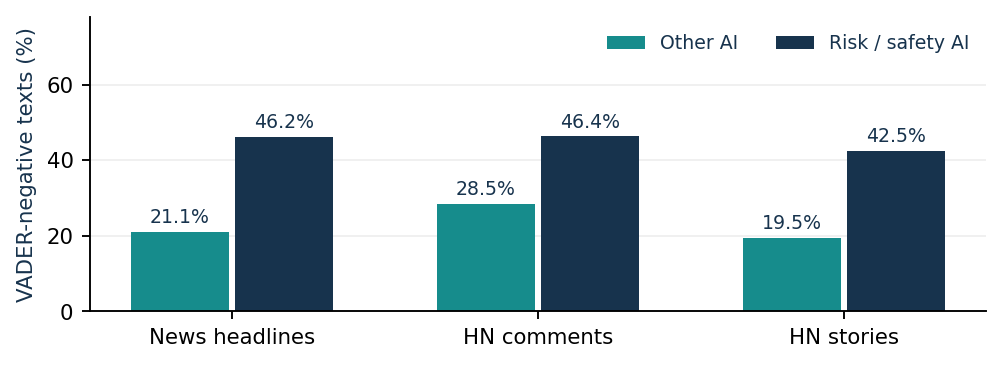

In [14]:
display(Image(filename=str(ROOT / 'outputs/bias_comparison.png')))

Figure 4. Negative wording within each text type. Different text lengths and populations prevent treating the cross-medium gap as a causal media effect.

Risk/safety headlines are 46.2% negative versus 21.1% for other AI headlines. Risk comments are 46.4% negative. Hu–Liu negative words average 8.2% of tokens in risk headlines and 4.2% in risk comments. These are measurable wording differences, but risk keywords and headline compression mechanically contribute to them.

**Comparable publisher groups.** For 1,429 headlines from 32 designated US/international publishers, a linear probability model controls publication-day effects, mutually exclusive risk-topic categories, log word count and its square. Standard errors cluster by publisher. US-group headlines are **6.56 percentage points less likely to be VADER-negative** (US-coefficient 95% interval -11.61 to -1.51 pp; p=0.011; two-measure Holm p=0.022). The manually specified groups differ from the COVID paper’s outlet universe.

The Hu–Liu comparison is -0.379 pp in negative-token share (p=0.322; 95% interval -1.130 to 0.372 pp). The two measures do not provide equally strong evidence for this source-group difference. The VADER point estimate runs in the direction opposite to the assigned study. Date/topic/length controls reduce observed composition differences but do not match every event or remove search-ranking selection.

**Attention selection.** HN stories with at least 5 snapshot points are 30.1% negative versus 19.7% below 5; risk-topic shares are 17.5% versus 11.4%. These are engagement-conditioned descriptions: age, exposure, topic and platform ranking also affect points. The comparison cannot establish reader demand or an ex-ante trading rule.

The defensible bias finding is a **sample-dependent asymmetry in wording and attention**. There is no observable daily ground-truth series for existential AI risk comparable to COVID case counts. The analysis cannot establish that journalists exaggerate risk, that negative reporting is false, or that the technology community represents the wider public.

In [15]:
print('bias_descriptive')
display(pd.read_csv(ROOT / 'outputs/bias_descriptive.csv'))

bias_descriptive


,medium,risk,n,sentiment,negative_share,hu_negative,risk_share
0,HN comments,False,32635.0,0.2326,0.2855,0.0267,0.0
1,HN comments,True,6442.0,0.0298,0.4637,0.0422,1.0
2,HN stories,False,3983.0,0.1003,0.1948,0.0281,0.0
3,HN stories,True,598.0,0.0072,0.4247,0.0717,1.0
4,News headlines,False,4543.0,0.0717,0.2109,0.0309,0.0
5,News headlines,True,1143.0,-0.0704,0.4619,0.0821,1.0


In [16]:
print('news_group_bias')
display(pd.read_csv(ROOT / 'outputs/news_group_bias.csv'))

news_group_bias


,source_group,risk,n,sentiment,negative_share,hu_negative,risk_share
0,International major,False,391.0,-0.0166,0.3120,0.0403,0.0
1,International major,True,155.0,-0.1361,0.5419,0.0862,1.0
2,Other / unclassified,False,3545.0,0.0902,0.1961,0.0293,0.0
3,Other / unclassified,True,712.0,-0.0526,0.4466,0.0791,1.0
4,US major,False,607.0,0.0203,0.2323,0.0346,0.0
5,US major,True,276.0,-0.0795,0.4565,0.0874,1.0


In [17]:
print('bias_regressions')
display(pd.read_csv(ROOT / 'outputs/bias_regressions.csv'))

bias_regressions


,model,term,n,clusters,coefficient,se,p,ci_low,ci_high,covariance,p_holm
0,negative,US major vs international major,1429,32,-0.0656,0.0258,0.0108,-0.1161,-0.0151,publisher-clustered,0.0217
1,hu_pct,US major vs international major,1429,32,-0.3795,0.3832,0.3220,-1.1305,0.3716,publisher-clustered,0.3220


In [18]:
print('engagement_bias')
display(pd.read_csv(ROOT / 'outputs/engagement_bias.csv'))

engagement_bias


,high_engagement,n,risk_share,negative_share,mean_sentiment
0,False,3373,0.1144,0.1975,0.1033
1,True,1208,0.1755,0.3013,0.0459


## 6  Investment interpretation and references

**Investment decision.** I would not trade this basket from the sign of the daily sentiment index. Its 2.72% return differs from SPY by +3.45 pp and QQQ by -0.28 pp. META returns 17.67%; the daily-rebalanced basket excluding META returns -0.25%. These comparisons show how stock composition affects the basket result. Benchmark subtraction is a relative return, not CAPM alpha or evidence that AI-risk news drove returns.

For an AI allocation, I would retain a diversified, separately risk-budgeted exposure and use risk coverage as a prompt for company-specific research: safety incidents, cloud demand, regulation, liability and investment spending. A high-reach warning can change the research agenda without supplying a statistically reliable buy/sell signal. I would require a longer out-of-sample window, contemporaneous text vintages, realistic trading costs and stable results across sources before permitting sentiment to change portfolio weights.

**Limits and reproducibility.** The study includes the September 30 close. Text ends at 16:00 New York time that day, so late-evening discussion is outside the sample. Short time series, capped retrieval, HN selection, imperfect risk rules, revisions and absent historical reach metrics prevent definitive causal or population-wide conclusions. The notebook exposes filters and model variants; cached source responses and hashes preserve the analyzed observations.

**Reproducibility.** The [repository](https://github.com/ph2606/FRE-GY-7871A-Assignment4) contains code, the executed notebook, dependencies, tests and an accurate AI-use statement. Raw texts, market data and generated data tables stay local and are excluded from Git. The PDF is a separate submission artifact. Codex provided substantial assistance; qualitative review is AI-assisted and does not substitute for independent student verification.

**References and data sources**

[1] Hubinger, E. (September 8, 2026). [X post](https://x.com/EvanHub/status/2097497037956891126). Assignment-provided event statement; no X corpus or verified reach metrics used.

[2] Sacerdote, B., Sehgal, R., and Cook, M. (2020). [Why Is All COVID-19 News Bad News?](https://www.nber.org/system/files/working_papers/w28110/w28110.pdf), NBER Working Paper 28110. Assigned November 2020 version.

[3] Carvalho, J., and Plastino, A. (2020). [On the evaluation and combination of state-of-the-art features in Twitter sentiment analysis](https://doi.org/10.1007/s10462-020-09895-6). Artificial Intelligence Review.

[4] Psomakelis, E., et al. (2014). [Comparing Methods for Twitter Sentiment Analysis](https://doi.org/10.5220/0005075302250232). KDIR, 225–232.

[5] Hutto, C. J., and Gilbert, E. (2014). [VADER](https://github.com/cjhutto/vaderSentiment), ICWSM; Hu, M., and Liu, B. (2004), [Mining and Summarizing Customer Reviews](https://doi.org/10.1145/1014052.1014073), KDD. Hu–Liu word lists from the archived NLTK corpus.

[6] [HN Algolia Search API](https://hn.algolia.com/api). Archived timestamp-filtered responses; [Hacker News API](https://github.com/HackerNews/API) for field definitions. [7] [Google News](https://news.google.com/) dated RSS search and [Guardian AI archive](https://www.theguardian.com/technology/artificialintelligenceai). Exact requests and publication clocks are in local manifests.

[8] [Yahoo Finance historical prices](https://finance.yahoo.com/quote/NVDA/history/), chart endpoints for the eight listed securities; archived adjusted and raw closes. [9] [statsmodels Granger documentation](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.grangercausalitytests.html). Software version 0.14.4; independent tests check F-test equivalence.

In [19]:
print('basket_exclusions')
display(pd.read_csv(ROOT / 'outputs/basket_exclusions.csv'))

basket_exclusions


,excluded,return_pct
0,NVDA,3.3801
1,MSFT,2.6940
2,GOOGL,2.8885
3,AMZN,4.0170
4,META,-0.2519
5,AVGO,3.5589


## Reconciliation and source audit

The following checks validate counts and dates, not sentiment accuracy or structural causality. Detailed document-level flags, source requests and review texts remain local. The saved notebook contains aggregate exhibits only.

In [20]:
news = json.loads((ROOT / 'outputs/news_manifest.json').read_text())
social = json.loads((ROOT / 'outputs/social_audit.json').read_text())
assert news['raw_discovered_rows'] == news['included_headlines'] + sum(news['exclusions'].values())
assert social['unique_candidate_ids'] == social['clean_records'] + sum(x['removed_at_stage'] for x in social['filter_flow'])
assert social['unresolved_truncated_leaf_requests'] == 0
docs = pd.read_csv(ROOT / 'data/processed/scored_documents.csv', low_memory=False)
kept = docs.loc[docs.included_analysis]
assert not kept.id.duplicated().any()
assert pd.to_datetime(kept.date).max() <= pd.Timestamp(CUTOFF)
assert len(kept) == sum(summary['documents'].values())
print('Counts, uniqueness, cutoff and HN query completeness checks passed.')
display(pd.read_csv(ROOT / 'outputs/language_summary_by_type.csv'))

Counts, uniqueness, cutoff and HN query completeness checks passed.


,kind,record_type,records,predicted_non_english,english_at_050,english_at_090,short_under_10_words,detector_failures,predicted_non_english_pct
0,news,headline,6423,126,6292,5981,1578,0,1.9617
1,social,comment,39175,111,39061,38897,799,0,0.2833
2,social,story,4745,151,4585,4381,1719,1,3.1823
